# Question 3 — Segmentation des données `aiguillage`

L’objectif est de segmenter une séquence de **140 observations**, décrites chacune par **552 variables**, en **quatre classes** à l’aide de l’algorithme de Fisher.

Nous comparons ensuite la partition obtenue :
- à la **partition de référence**, fournie dans la 553ᵉ colonne du fichier ;
- aux partitions calculées par **K-means** et la **classification ascendante hiérarchique (CAH) de Ward**.

Cette comparaison permet d’étudier l’apport de la **contrainte d’ordre** : Fisher construit des segments successifs, tandis que K-means et Ward regroupent les observations sans imposer leur contiguïté dans la séquence.


## 1. Imports

Nous importons les fonctions de classification **Fisher, K-means et Ward**, ainsi que les critères d’évaluation définis dans `utils.py` : **inertie, ARI et silhouette**.


In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA

from utils import (
    clustfisher, clustkmeans, clustward,
    inertie, compare_partitions, silhouette,
)

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
couleurs = ["#2563eb", "#d97706", "#059669", "#9333ea"]

## 2. Chargement et préparation des données

Le fichier `aiguillage.txt` contient **140 observations et 553 colonnes** :

- les **552 premières colonnes** décrivent les observations et constituent la matrice `X` ;
- la **553ᵉ colonne** contient les vraies classes, conservées dans le vecteur `y` uniquement pour évaluer les partitions obtenues.

Nous conservons **l’ordre initial des lignes**, indispensable à la segmentation de Fisher. Les trois méthodes sont appliquées aux mêmes données brutes, **sans standardisation**, afin de comparer leurs résultats avec le même critère d’inertie sur les valeurs d’origine.

Le nombre de classes est fixé à **K = 4**, conformément à l’énoncé.

In [2]:
chemin = Path("data/aiguillage.txt")
donnees = np.loadtxt(chemin, delimiter=",")

X = donnees[:, :-1]
y = donnees[:, -1].astype(int)
n, p = X.shape
K = 4

assert donnees.shape == (140, 553), "La dimension du fichier est inattendue."
assert np.isfinite(donnees).all(), "Le fichier contient des valeurs manquantes ou infinies."
assert np.array_equal(np.unique(y), [1, 2, 3, 4])

print(f"Nombre d'observations : {n}")
print(f"Nombre de variables : {p}")
print(f"Nombre de classes demandé : {K}")

effectifs = pd.Series(y).value_counts().sort_index()
effectifs.index.name = "Vraie classe"
display(effectifs.to_frame("Effectif"))

Nombre d'observations : 140
Nombre de variables : 552
Nombre de classes demandé : 4


,Effectif
Vraie classe,
1,35
2,40
3,45
4,20


<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des données : </strong>

  <p>
    Le jeu de données comprend <strong>140 observations</strong>,
    chacune décrite par <strong>552 variables</strong>.
    Le nombre de classes est fixé à quatre, conformément à l’énoncé.
  </p>

  <p>
    Les classes de référence comptent respectivement
    <strong>35, 40, 45 et 20 observations</strong>.
    Leurs effectifs sont inégaux : la classe 3 est la plus représentée,
    tandis que la classe 4 est la moins représentée.
    Les méthodes ne sont pas contraintes de former des groupes de même taille.
  </p>

  <p style="margin-bottom: 0;">
    Les vraies classes servent uniquement à l’évaluation.
    Leurs labels et leurs effectifs ne sont pas fournis aux algorithmes,
    qui construisent leurs partitions à partir des 552 variables.
  </p>
</div>

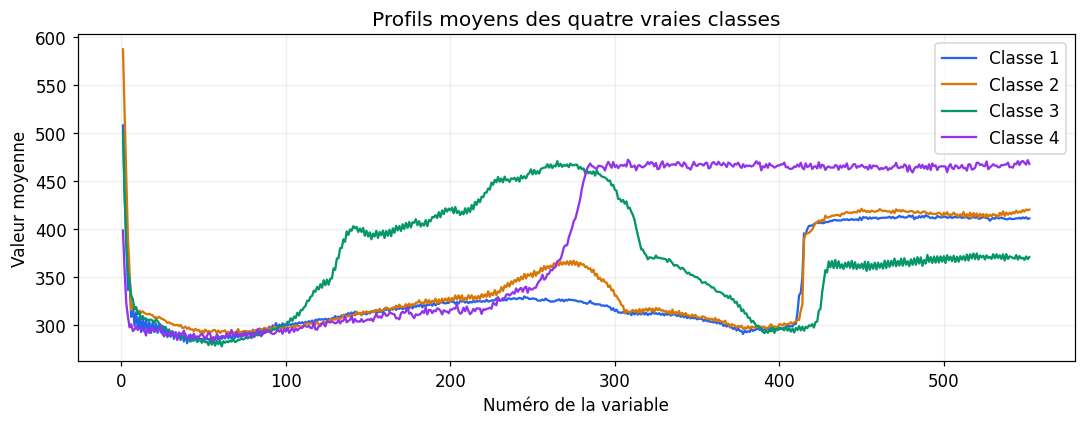

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
for classe in range(1, K + 1):
    profil = X[y == classe].mean(axis=0)
    ax.plot(np.arange(1, p + 1), profil,
            color=couleurs[classe - 1], label=f"Classe {classe}")

ax.set(title="Profils moyens des quatre vraies classes",
       xlabel="Numéro de la variable", ylabel="Valeur moyenne")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des profils moyens</strong>

  <p>
    Les classes <strong>3 et 4</strong> présentent des profils moyens
    distincts. La classe 3 augmente fortement dans la partie centrale,
    puis diminue, tandis que la classe 4 atteint un plateau élevé
    autour de la variable 280 et le conserve jusqu’à la fin.
  </p>

  <p>
    Les classes <strong>1 et 2</strong> ont des profils proches sur
    une grande partie des variables. Une différence apparaît notamment
    entre les variables 230 et 300, où la classe 2 présente
    une élévation plus marquée.
    Cette ressemblance peut rendre leur séparation plus difficile
    pour les méthodes fondées sur les distances.
  </p>

  <p style="margin-bottom: 0;">
    Ces courbes représentent des moyennes : elles ne montrent pas
    la dispersion des observations dans chaque classe.
    La distinction des profils moyens ne garantit donc pas,
    à elle seule, une classification parfaite.
  </p>
</div>

## 3. Application de Fisher, K-means et de la CAH de Ward

Les trois méthodes sont appliquées aux mêmes données, avec **K = 4**, conformément à l’énoncé.

- **Fisher** construit quatre segments contigus en respectant l’ordre des observations.
- **K-means** regroupe les observations autour de quatre centres, sans contrainte d’ordre. Nous utilisons dix initialisations et conservons la solution de plus faible inertie. Une graine fixe permet de reproduire le calcul.
- **La CAH de Ward** fusionne progressivement les groupes en limitant l’augmentation de l’inertie, puis fournit une partition en quatre classes, sans contrainte d’ordre.

Les temps de calcul sont mesurés à titre indicatif. Ils correspondent à une seule exécution sur notre ordinateur et ne permettent pas d’établir un classement général des méthodes.

In [4]:
temps = {}

debut = time.perf_counter()
t, cluster_fisher, C_fisher = clustfisher(X, K)
temps["Fisher"] = time.perf_counter() - debut

debut = time.perf_counter()
cluster_kmeans, C_kmeans = clustkmeans(X, K)
temps["K-means"] = time.perf_counter() - debut

debut = time.perf_counter()
cluster_ward, C_ward = clustward(X, K)
temps["Ward"] = time.perf_counter() - debut

partitions = {
    "Fisher": cluster_fisher,
    "K-means": cluster_kmeans,
    "Ward": cluster_ward,
}
criteres = {"Fisher": C_fisher, "K-means": C_kmeans, "Ward": C_ward}

ruptures_vraies = np.where(y[1:] != y[:-1])[0] + 2   # débuts des nouvelles vraies classes
print("Débuts des nouveaux segments de Fisher :", t)
print("Débuts des nouvelles vraies classes     :", ruptures_vraies)
print("Ruptures identiques :", np.array_equal(t, ruptures_vraies))
bornes = np.r_[1, t, n + 1]
segments = pd.DataFrame({
    "Classe": np.arange(1, K + 1),
    "Première observation": bornes[:-1],
    "Dernière observation": bornes[1:] - 1,
    "Effectif": np.diff(bornes),
})
display(segments)

Débuts des nouveaux segments de Fisher : [ 36  76 121]
Débuts des nouvelles vraies classes     : [ 36  76 121]
Ruptures identiques : True


,Classe,Première observation,Dernière observation,Effectif
0,1,1,35,35
1,2,36,75,40
2,3,76,120,45
3,4,121,140,20


<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation de la segmentation de Fisher</strong>

  <p>
    Fisher situe les débuts des nouveaux segments aux observations
    <strong>36, 76 et 121</strong>. Ces positions correspondent
    exactement aux changements de classes de la partition de référence,
    comme le confirme la comparaison des ruptures.
  </p>

  <p>
    La séquence est ainsi découpée en quatre intervalles :
    <strong>1–35, 36–75, 76–120 et 121–140</strong>,
    contenant respectivement 35, 40, 45 et 20 observations.
    Chaque rupture désigne la première observation du nouveau segment :
    le deuxième segment commence donc à 36, après un premier segment
    se terminant à 35.
  </p>

  <p style="margin-bottom: 0;">
    Fisher retrouve ainsi les frontières et les effectifs des quatre
    classes de référence. Sur ces données, la contrainte de contiguïté
    est cohérente avec la structure des vraies classes,
    qui se succèdent par blocs dans la séquence.
  </p>
</div>

## 4. Évaluation des partitions

Nous comparons les trois méthodes avec quatre critères :

- **Inertie** : plus elle est faible, plus les groupes sont compacts.
- **ARI** : mesure l’accord avec les vraies classes ; un score de 1 indique une partition identique.
- **Silhouette** : plus elle est proche de 1, mieux les groupes sont séparés.
- **Nombre de changements de classe** : indique si les groupes sont dispersés dans la séquence.

Les trois méthodes utilisent les mêmes données et le même nombre de classes, **K = 4**.

In [5]:
lignes = []
for nom, cluster in partitions.items():
    lignes.append({
        "Méthode": nom,
        "Inertie": criteres[nom],
        "ARI avec la vérité": compare_partitions(y, cluster),
        "Silhouette": silhouette(X, cluster),
        "Changements de classe": int(np.sum(cluster[1:] != cluster[:-1])),
        "Temps indicatif (s)": f"{temps[nom]:.2f}",
    })

resultats = pd.DataFrame(lignes).set_index("Méthode")
display(resultats)
print(f"Inertie des vraies classes : {inertie(X, y):,.2f}")

,Inertie,ARI avec la vérité,Silhouette,Changements de classe,Temps indicatif (s)
Méthode,,,,,
Fisher,"10,457,794.8237",1.0000,0.5070,3,2.94
K-means,"10,346,192.9897",0.9426,0.5123,9,0.56
Ward,"10,599,309.7344",0.8589,0.4978,7,0.04


Inertie des vraies classes : 10,457,794.82


<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des résultats</strong>

  <p>
    <strong>Fisher retrouve exactement les vraies classes</strong>,
    avec un ARI de 1. Son inertie est identique à celle de la partition
    de référence et ses trois changements correspondent aux frontières
    des quatre segments.
  </p>

  <p>
    <strong>K-means obtient l’inertie la plus faible</strong>,
    mais son ARI est légèrement inférieur (environ 0,94).
    Ses groupes sont donc plus compacts, tout en s’éloignant
    des vraies classes. Ses neuf changements montrent
    qu’ils ne sont pas tous contigus dans la séquence.
  </p>

  <p>
    <strong>Ward retrouve moins fidèlement la partition de référence</strong>,
    avec un ARI d’environ 0,86. Son inertie est la plus élevée
    des trois méthodes, et il produit sept changements de classe.
  </p>

  <p>
    L’écart d’inertie entre Fisher et K-means est attendu :
    <strong>Fisher minimise l’inertie parmi les seules partitions
    en segments contigus</strong>, alors que K-means n’a pas
    cette contrainte et peut donc former des groupes plus compacts.
    Une meilleure compacité ne garantit donc pas un meilleur accord
    avec les vraies classes.
  </p>

  <p style="margin-bottom: 0;">
    Les silhouettes sont proches, autour de 0,5. K-means obtient
    un score légèrement supérieur, mais l’écart reste faible.
    Cet indice mesure la séparation géométrique des groupes,
    pas leur accord avec les vraies classes. Les temps affichés
    restent indicatifs et ne permettent pas de généraliser
    les différences de rapidité observées.
  </p>
</div>

ARI entre toutes les partitions, deux à deux :

In [6]:
toutes = {"Vérité": y, **partitions}
matrice_ari = pd.DataFrame(
    [[compare_partitions(a, b) for b in toutes.values()] for a in toutes.values()],
    index=list(toutes), columns=list(toutes),
)
display(matrice_ari)

,Vérité,Fisher,K-means,Ward
Vérité,1.0000,1.0000,0.9426,0.8589
Fisher,1.0000,1.0000,0.9426,0.8589
K-means,0.9426,0.9426,1.0000,0.8747
Ward,0.8589,0.8589,0.8747,1.0000


<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Comparaison des partitions deux à deux</strong>

  <p>
    L’ARI entre <strong>Fisher et la vérité vaut 1</strong> :
    les deux partitions sont identiques. Leurs accords avec
    K-means et Ward sont donc également identiques.
  </p>

  <p>
    <strong>K-means est plus proche de la référence</strong>
    (ARI ≈ 0,94) que Ward (ARI ≈ 0,86).
    L’ARI entre K-means et Ward vaut environ <strong>0,87</strong> :
    ces méthodes produisent des regroupements proches, mais différents.
  </p>

  <p style="margin-bottom: 0;">
    Les valeurs de 1 sur la diagonale correspondent à la comparaison
    de chaque partition avec elle-même. L’ARI compare les regroupements,
    indépendamment des numéros attribués aux classes.
  </p>
</div>

## 5. Désaccords avec la vraie partition

Les numéros des groupes sont arbitraires : un groupe appelé « 1 » peut correspondre à la vraie classe « 3 ».

Nous renommons donc les groupes pour obtenir la meilleure correspondance avec les vraies classes, puis nous comptons les observations en désaccord. Ce renommage ne modifie ni les groupes ni les scores calculés.

In [7]:
def renommer_classes(cluster, y):
    """Associer les numéros des groupes aux vraies classes pour l'affichage."""
    tableau = np.zeros((K, K), dtype=int)
    for i in range(K):
        for j in range(K):
            tableau[i, j] = np.sum((y == i + 1) & (cluster == j + 1))

    # Meilleure correspondance globale entre les quatre numéros de classes
    lignes, colonnes = linear_sum_assignment(-tableau)
    nouveaux_labels = np.zeros(n, dtype=int)
    for i, j in zip(lignes, colonnes):
        nouveaux_labels[cluster == j + 1] = i + 1
    return nouveaux_labels

partitions_affichage = {}
for nom, cluster in partitions.items():
    partitions_affichage[nom] = renommer_classes(cluster, y)

for nom, cluster in partitions_affichage.items():
    tableau = pd.crosstab(
        pd.Series(y, name="Vraie classe"),
        pd.Series(cluster, name="Classe calculée"),
    ).reindex(index=range(1, K + 1), columns=range(1, K + 1), fill_value=0)
    print(f"{nom} — {np.sum(cluster != y)} observations en désaccord après renommage")
    display(tableau)
    desaccords = np.where(cluster != y)[0] + 1
    if len(desaccords) > 0:
        print("Observations concernées :", desaccords, "\n")

Fisher — 0 observations en désaccord après renommage


Classe calculée,1,2,3,4
Vraie classe,,,,
1,35,0,0,0
2,0,40,0,0
3,0,0,45,0
4,0,0,0,20


K-means — 3 observations en désaccord après renommage


Classe calculée,1,2,3,4
Vraie classe,,,,
1,34,1,0,0
2,2,38,0,0
3,0,0,45,0
4,0,0,0,20


Observations concernées : [22 67 69] 

Ward — 8 observations en désaccord après renommage


Classe calculée,1,2,3,4
Vraie classe,,,,
1,28,7,0,0
2,1,39,0,0
3,0,0,45,0
4,0,0,0,20


Observations concernées : [19 20 21 22 23 24 25 67] 



<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des désaccords</strong>

  <p>
    Les lignes correspondent aux vraies classes et les colonnes aux
    classes calculées après renommage. Les valeurs sur la diagonale
    représentent les observations correctement regroupées ;
    celles hors diagonale indiquent les désaccords.
  </p>

  <p>
    <strong>Fisher ne présente aucun désaccord</strong> :
    les 140 observations sont sur la diagonale.
    Il retrouve donc exactement la partition de référence.
  </p>

  <p>
    <strong>K-means présente trois désaccords</strong> :
    l’observation 22 passe de la vraie classe 1 au groupe 2,
    tandis que les observations 67 et 69 passent de la vraie
    classe 2 au groupe 1.
  </p>

  <p>
    <strong>Ward présente huit désaccords</strong> :
    les observations 19 à 25 de la vraie classe 1 sont regroupées
    avec la classe 2, et l’observation 67 de la vraie classe 2
    est regroupée avec la classe 1.
  </p>

  <p style="margin-bottom: 0;">
    Les différences concernent uniquement les <strong>classes 1 et 2</strong>,
    dont les profils moyens sont proches. Les classes 3 et 4 sont
    retrouvées par les trois méthodes. Les observations 22 et 67
    sont en désaccord avec la référence à la fois pour K-means et Ward,
    ce qui justifierait un examen individuel de leurs profils.
  </p>
</div>

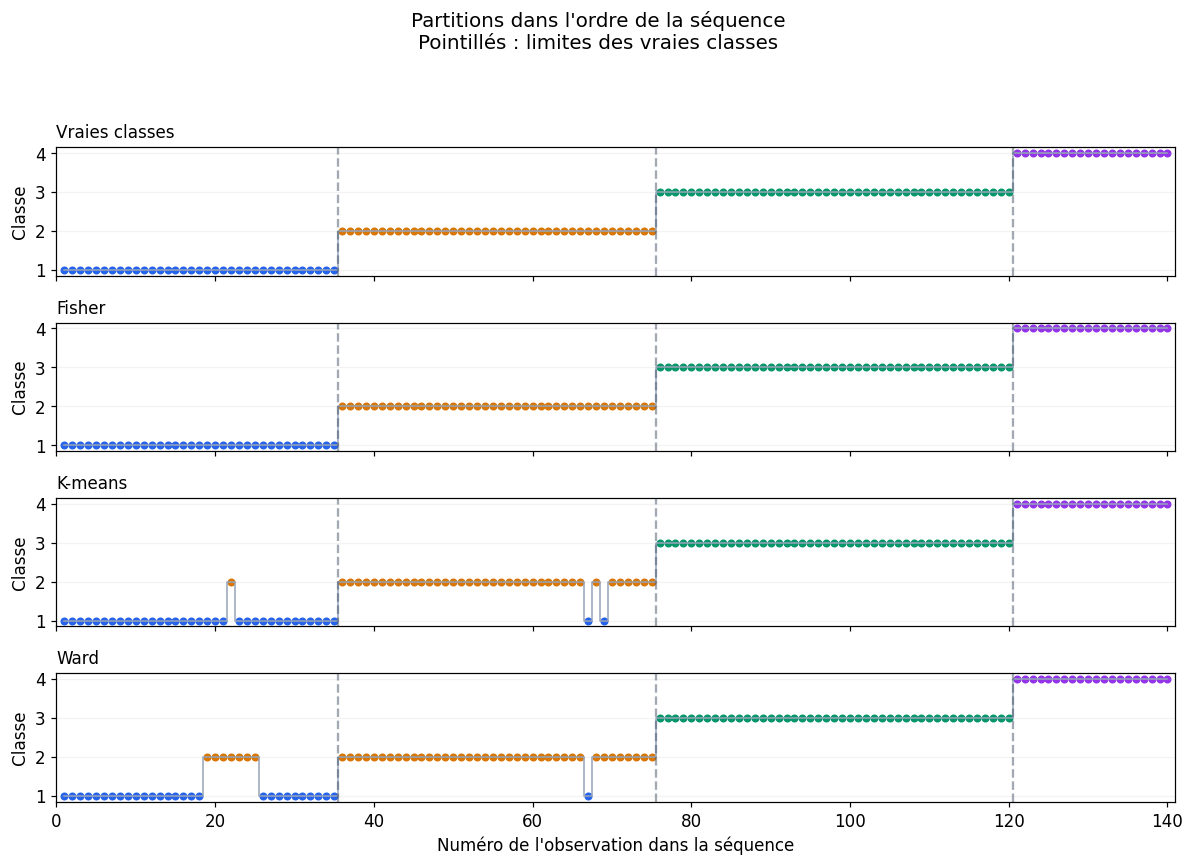

In [8]:
observations = np.arange(1, n + 1)

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True, sharey=True)
a_afficher = {"Vraies classes": y, **partitions_affichage}

for ax, (nom, cluster) in zip(axes, a_afficher.items()):
    ax.step(observations, cluster, where="mid", color="#94a3b8", linewidth=1)
    for classe in range(1, K + 1):
        masque = cluster == classe
        ax.scatter(observations[masque], cluster[masque], s=18,
                   color=couleurs[classe - 1])
    for rupture in ruptures_vraies:
        ax.axvline(rupture - 0.5, color="#475569", linestyle="--", alpha=0.5)
    ax.set_title(nom, loc="left", fontsize=11)
    ax.set_yticks(range(1, K + 1))
    ax.set_ylabel("Classe")
    ax.grid(axis="y", alpha=0.15)

axes[-1].set_xlabel("Numéro de l'observation dans la séquence")
axes[-1].set_xlim(0, n + 1)
fig.suptitle("Partitions dans l'ordre de la séquence\nPointillés : limites des vraies classes", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des partitions dans la séquence</strong>

  <p>
    Les pointillés indiquent les frontières des vraies classes.
    <strong>Fisher reproduit exactement les quatre segments de référence</strong>,
    avec des changements aux observations 36, 76 et 121.
  </p>

  <p>
    <strong>K-means et Ward présentent des allers-retours entre les
    classes 1 et 2.</strong> K-means réaffecte quelques observations
    isolées, tandis que Ward attribue notamment le bloc 19–25
    au groupe associé à la classe 2. Les deux méthodes retrouvent
    les segments correspondant aux classes 3 et 4.
  </p>

  <p style="margin-bottom: 0;">
    Ce graphique illustre l’apport de la <strong>contrainte d’ordre</strong> :
    Fisher construit des groupes contigus, alors que K-means et Ward
    peuvent réunir des observations éloignées dans la séquence.
    Sur ces données, cette contrainte permet de retrouver la continuité
    des classes de référence.
  </p>
</div>

## 6. Visualisation des partitions par ACP

Chaque observation possède 552 variables. Nous utilisons une **analyse en composantes principales (ACP)** pour représenter les observations sur deux axes et visualiser la séparation des groupes.

Les mêmes points sont colorés selon les vraies classes, puis selon chaque partition calculée. L’ACP sert uniquement à la visualisation : **les trois classifications ont été réalisées sur les 552 variables d’origine**.

Variance expliquée par les deux axes : 93.30 %


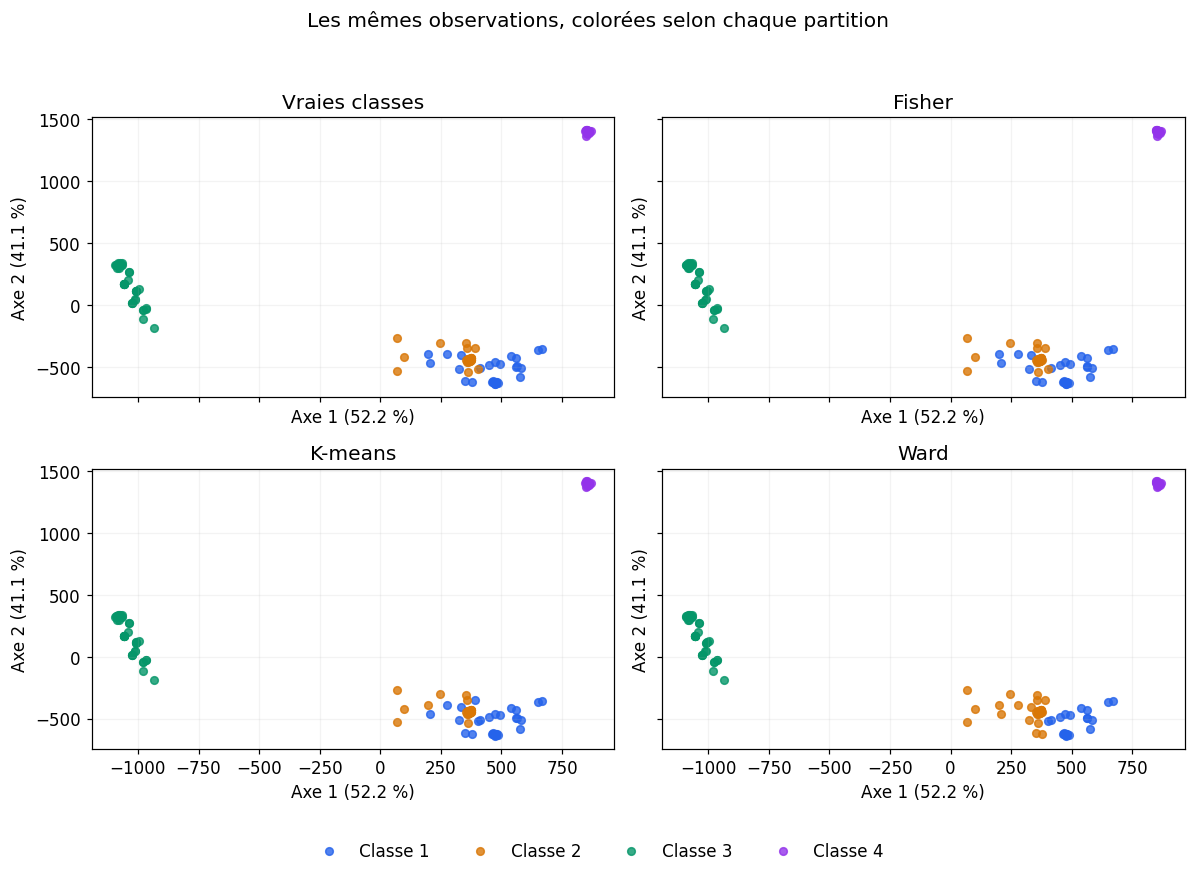

In [9]:
acp = PCA(n_components=2, svd_solver="full")
coordonnees = acp.fit_transform(X)
variance = acp.explained_variance_ratio_ * 100
print(f"Variance expliquée par les deux axes : {variance.sum():.2f} %")

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, (nom, cluster) in zip(axes.flat, a_afficher.items()):
    for classe in range(1, K + 1):
        masque = cluster == classe
        ax.scatter(coordonnees[masque, 0], coordonnees[masque, 1],
                   s=25, alpha=0.8, color=couleurs[classe - 1],
                   label=f"Classe {classe}")
    ax.set_title(nom)
    ax.set_xlabel(f"Axe 1 ({variance[0]:.1f} %)")
    ax.set_ylabel(f"Axe 2 ({variance[1]:.1f} %)")
    ax.grid(alpha=0.15)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Les mêmes observations, colorées selon chaque partition")
fig.tight_layout(rect=(0, 0.06, 1, 0.95))
plt.show()

<div style="box-sizing: border-box; width: 100%; padding: 14px 18px;
            background-color: #f0f7ff; color: #243447;
            border-left: 3px solid #93c5fd; border-radius: 6px;
            line-height: 1.7; overflow-wrap: break-word;">

  <strong>Interprétation de l’ACP</strong>

  <p>
    Les deux axes expliquent <strong>93,3 % de la variance</strong>.
    Les classes 3 et 4 sont bien séparées sur ce plan,
    tandis que les classes 1 et 2 se recouvrent partiellement.
  </p>

  <p style="margin-bottom: 0;">
    Fisher reproduit la coloration des vraies classes.
    Les différences de K-means et Ward concernent les classes 1 et 2,
    conformément aux désaccords observés.
    Cette projection reste une représentation simplifiée des 552 variables.
  </p>
</div>

## 7. Robustesse

### 7.1 Influence de l’ordre des observations — analyse complémentaire

Nous mélangeons les lignes cinq fois, puis appliquons Fisher et K-means pour observer l’effet de l’ordre. Les vraies classes sont permutées de la même façon afin de conserver leur correspondance avec les observations.

In [10]:
rng = np.random.default_rng(0)
lignes_melange = []
for essai in range(1, 6):
    permutation = rng.permutation(n)
    X_melange, y_melange = X[permutation], y[permutation]
    _, cluster_fisher_m, _ = clustfisher(X_melange, K)
    cluster_kmeans_m, _ = clustkmeans(X_melange, K)
    lignes_melange.append({
        "Mélange": essai,
        "ARI Fisher": compare_partitions(y_melange, cluster_fisher_m),
        "ARI K-means": compare_partitions(y_melange, cluster_kmeans_m),
    })

melange = pd.DataFrame(lignes_melange).set_index("Mélange")
display(melange)

,ARI Fisher,ARI K-means
Mélange,,
1,0.0266,0.9426
2,0.0116,0.9426
3,0.0139,0.9426
4,0.0098,0.9426
5,0.0144,0.9426


<div style="box-sizing: border-box; width: 100%; padding: 14px 18px;
            background-color: #f0f7ff; color: #243447;
            border-left: 3px solid #93c5fd; border-radius: 6px;
            line-height: 1.7; overflow-wrap: break-word;">

  <strong>Influence du mélange des lignes</strong>

  <p>
    Après mélange, l’ARI de Fisher devient proche de zéro
    (<strong>0,010 à 0,027</strong>). Les vraies classes étant désormais
    dispersées dans la séquence, quatre segments contigus
    ne permettent plus de les retrouver.
  </p>

  <p style="margin-bottom: 0;">
    K-means conserve ici un <strong>ARI d’environ 0,943</strong>
    sur les cinq essais. Cette expérience montre que la contrainte
    d’ordre de Fisher est utile lorsque les classes recherchées
    se succèdent effectivement dans la séquence.
  </p>
</div>

## 8. Conclusion

| Méthode | ARI avec la vérité | Désaccords après renommage |
|---|---:|---:|
| Fisher | 1,00 | 0 |
| K-means | 0,94 | 3 |
| Ward | 0,86 | 8 |

<div style="box-sizing: border-box; width: 100%; padding: 14px 18px;
            background-color: #f0f7ff; color: #243447;
            border-left: 3px solid #93c5fd; border-radius: 6px;
            line-height: 1.7; overflow-wrap: break-word;">

  <p style="margin-top: 0;">
    <strong>Fisher retrouve exactement les quatre classes de référence</strong>,
    avec des débuts de segments aux observations 36, 76 et 121.
    K-means et Ward présentent respectivement trois et huit désaccords,
    uniquement entre les classes 1 et 2.
  </p>

  <p>
    K-means obtient une inertie plus faible, mais un accord moins bon
    avec les vraies classes. Ce n’est pas une contradiction :
    Fisher minimise l’inertie parmi les seules partitions en segments
    contigus, alors que K-means n’a pas cette contrainte.
    Une meilleure compacité ne garantit donc pas une meilleure
    reconnaissance de la partition de référence. Ici, les vraies classes
    se succèdent par blocs : <strong>la contrainte d’ordre apporte
    une information que K-means et Ward n’utilisent pas</strong>,
    et qui lève la confusion entre les classes 1 et 2.
  </p>

  <p>
    Fisher présente aussi un avantage de méthode : grâce à la
    programmation dynamique, il fournit <strong>l’optimum global</strong>
    de son critère, sans initialisation aléatoire. Pour les mêmes données,
    dans le même ordre et avec K fixé, il renvoie toujours la même partition.
  </p>

  <p style="margin-bottom: 0;">
    L’expérience des lignes mélangées confirme l’importance de cet ordre :
    lorsque les classes ne sont plus contiguës, Fisher ne les retrouve plus.
    Ces résultats concernent ce jeu de données, avec K = 4 ;
    ils ne démontrent pas une supériorité générale de Fisher.
  </p>
</div>